# Hipótese 7 — Falhas mecânicas de componentes

**Hipótese investigativa:** a maior parte das manutenções corretivas está associada a falhas mecânicas de componentes.

## 1. Definição inicial da investigação

Este notebook investigará as ordens de manutenção do sistema de Portas de Plataforma (PSD), buscando verificar se as falhas mecânicas representam mais de 50% das manutenções corretivas. Além do teste da hipótese, a investigação procurará identificar agrupamentos recorrentes de **causas** e **defeitos**, permitindo compreender quais mecanismos e modos de falha são mais incidentes.

### Escopo acordado

- **Unidade de análise:** uma ordem SAP única;
- **Ordens incluídas:** ZM01 (corretiva emergencial) e ZM02 (corretiva programada);
- **Ordens excluídas do teste principal:** ZM03 (preventiva), pois não necessariamente representam uma falha observada;
- **Critério geral:** uma ordem será considerada mecânica quando sua causa ou seu defeito estiver relacionado à degradação física ou ao funcionamento mecânico de um componente;
- **Limiar da hipótese:** haverá maioria quando a proporção de ordens mecânicas for superior a 50%.

### Perguntas investigativas

1. Qual proporção das ordens corretivas está associada a falhas mecânicas?
2. Quais grupos de causas aparecem com maior frequência?
3. Quais grupos de defeitos aparecem com maior frequência?
4. Quais combinações entre causa, defeito e componente são recorrentes?
5. Os agrupamentos diferem entre manutenções emergenciais e programadas?

> Neste momento, “cluster” significa um agrupamento de registros semelhantes. A escolha entre agrupamento por regras de domínio, técnicas de texto ou algoritmos não supervisionados será feita depois da inspeção dos campos e da qualidade dos dados.

### 1.1 Etapas previstas

1. Definir hipótese, escopo e perguntas investigativas;
2. Carregar as bases e conhecer suas colunas;
3. Avaliar dados ausentes, duplicidades e consistência dos diagnósticos;
4. Preparar uma base limpa, preservando os dados originais;
5. Padronizar os textos de causa e defeito;
6. Construir e validar os grupos de causas;
7. Construir e validar os grupos de defeitos;
8. Cruzar causas e defeitos e classificar a evidência mecânica;
9. Testar a hipótese e comparar ZM01 com ZM02;
10. Interpretar os resultados e registrar as limitações.

## 2. Carregamento e investigação inicial das bases

Nesta etapa apenas conheceremos os dados. Nenhuma ordem será classificada como mecânica e nenhum cluster será criado ainda.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 180)

# Caminhos relativos a partir da pasta eda/hipoteses.
data_ce_path = '../../data/Ordens do SAP - Corretiva emergencial (ZM01).XLSX'
data_cp_path = '../../data/Ordens do SAP -Corretiva programada (ZM02).XLSX'

df_ce = pd.read_excel(data_ce_path)
df_cp = pd.read_excel(data_cp_path)

print('Bases carregadas com sucesso.')

Bases carregadas com sucesso.


In [10]:
resumo_bases = pd.DataFrame({
    'Base': ['ZM01 - Corretiva emergencial', 'ZM02 - Corretiva programada'],
    'Linhas': [df_ce.shape[0], df_cp.shape[0]],
    'Colunas': [df_ce.shape[1], df_cp.shape[1]],
    'Ordens distintas': [df_ce['Ordem'].nunique(), df_cp['Ordem'].nunique()],
})
display(resumo_bases)

colunas_ce = set(df_ce.columns)
colunas_cp = set(df_cp.columns)
print('As bases possuem as mesmas colunas?', colunas_ce == colunas_cp)

display(pd.DataFrame({'Colunas disponíveis': df_ce.columns}))

,Base,Linhas,Colunas,Ordens distintas
0,ZM01 - Corretiva emergencial,10647,28,10574
1,ZM02 - Corretiva programada,1163,28,1153


As bases possuem as mesmas colunas? True


,Colunas disponíveis
0,Tipo de Nota
1,Nota
2,Ordem
3,Indisponível
4,Falha
5,IQM
6,Analisada
7,Comentários Classificação Engenharia
8,Perfil do catálogo
9,Descrição


### 2.1 Campos relevantes para a investigação

- `Causa`: motivo atribuído à ocorrência;
- `Defeito`: modo de falha registrado;
- `Objeto`: componente ou subsistema envolvido;
- `Sintoma`: manifestação observada;
- `Descrição`: resumo da ocorrência;
- `Texto Longo da Ordem`: relato detalhado da atuação.

Primeiro verificamos preenchimento e variedade. Células vazias e textos contendo apenas espaços são tratados como ausência somente para esta contagem; as bases originais permanecem inalteradas.

In [11]:
campos_textuais = ['Causa', 'Defeito', 'Objeto', 'Sintoma', 'Descrição', 'Texto Longo da Ordem']
resumo = []

for nome_base, base in [('ZM01', df_ce), ('ZM02', df_cp)]:
    for campo in campos_textuais:
        valores = base[campo].fillna('').astype(str).str.strip()
        preenchidos = valores.ne('').sum()
        resumo.append({
            'Base': nome_base,
            'Campo': campo,
            'Preenchidos': preenchidos,
            'Ausentes': len(base) - preenchidos,
            'Preenchimento (%)': 100 * preenchidos / len(base),
            'Valores distintos': valores[valores.ne('')].nunique()
        })

resumo_campos = pd.DataFrame(resumo)
display(resumo_campos.round({'Preenchimento (%)': 1}))

,Base,Campo,Preenchidos,Ausentes,Preenchimento (%),Valores distintos
0,ZM01,Causa,9602,1045,90.2,24
1,ZM01,Defeito,9661,986,90.7,103
2,ZM01,Objeto,9665,982,90.8,127
3,ZM01,Sintoma,10647,0,100.0,58
4,ZM01,Descrição,10647,0,100.0,3160
5,ZM01,Texto Longo da Ordem,10585,62,99.4,10514
6,ZM02,Causa,1121,42,96.4,21
7,ZM02,Defeito,1124,39,96.6,93
8,ZM02,Objeto,1124,39,96.6,112
9,ZM02,Sintoma,1163,0,100.0,57


In [12]:
print('Exemplos da ZM01')
display(df_ce[['Ordem', *campos_textuais]].head(3))

print('Exemplos da ZM02')
display(df_cp[['Ordem', *campos_textuais]].head(3))

Exemplos da ZM01


,Ordem,Causa,Defeito,Objeto,Sintoma,Descrição,Texto Longo da Ordem
0,53954586.0,NaN,NaN,NaN,LAÇO DE PDM ABERTO,PSD PL 01-02 Sem status para o CCO,PSD PL 01-02 Sem status para o CCO 14.11.2025 17:18:43 BRAZIL (28-01325) No início do turno a SSE da plataforma 02 estava sendo alimentada pela Barra B e o NVT P1 estava com o...
1,54145839.0,ERRO DE COMUNICAÇÃO,CONTROLADOR PCC COMUNICACAO,CABEAMENTO,TODAS AS PDM DA FACHADA NÃO ABREM,PSD - PDM's não abriram PLT02,PSD - PDM's não abriram PLT02 27.02.2026 14:20:07 BRAZIL (28-03341) Ordem sendo tratada na OS 53954586.
2,52913343.0,DESGASTE,SENSOR DESTRAVADO AVARIADO,RACK WCN,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,PSD server s/ status das plataformas,"PSD server s/ status das plataformas 18.04.2024 07:28:58 BRAZIL ADILSON PEREIRA DOS SANTOS (28-01926) Durante a operação o PSD sever apresentou falha na comunicação com o CCO, ..."


Exemplos da ZM02


,Ordem,Causa,Defeito,Objeto,Sintoma,Descrição,Texto Longo da Ordem
0,54081268.0,FALTA FIXACAO,PORTA DESAJUSTADA,"ESTRUTURA, ACABAMENTO, E ACESSÓRIOS DO P",PDM NÃO ABRE,Porta PCC-PSD a,"Porta PCC-PSD 25.01.2026 08:29:08 BRAZIL (28-01325) 25.01.2026 16:43:35 BRAZIL (28-04512) Realizado a instalação de um trinco na porta traseira do PCC-PSD, a fim de evitar a a..."
1,53659484.0,ERRO DE SOFTWARE,SEM CONEXAO ELETRICA,SWITCK DE COMUNICAÇÃO,MAU CONTATO,PDMs plat 1 e 2 com falha momentânea.,"PDMs plat 1 e 2 com falha momentânea. 30.05.2025 14:24:19 BRAZIL DENIS RODRIGUES DO NASCIMENTO (28-04212) O CCO informou que as plataformas não prestou serviço, feito reciclo p..."
2,53694340.0,OPERACAO INDEVIDA,CONVERSOR DE TENSAO AVARIADO,DISPOSITIVO DE PROTECAO,FACHADA PSD SEM ALIMENTAÇÃO,Rele painel SSE intermitente,"Rele painel SSE intermitente 19.06.2025 05:05:07 BRAZIL D. DE MELO SOARES (28-00570) Tel. 55 11 458.. Realizado a substituição do Relé P2 VNT-coel da SSE da plataforma 2, o mes..."


### 2.2 Primeira observação de causas e defeitos

As frequências abaixo ajudam a responder se `Causa` e `Defeito` já possuem categorias padronizadas ou se exigirão agrupamento textual. Ainda não unimos grafias semelhantes nem atribuímos natureza mecânica.

In [ ]:
print('ZM01 — causas mais frequentes')
display(df_ce['Causa'].value_counts().head(15).to_frame('Quantidade'))

print('ZM01 — defeitos mais frequentes')
display(df_ce['Defeito'].value_counts().head(15).to_frame('Quantidade'))

print('ZM02 — causas mais frequentes')
display(df_cp['Causa'].value_counts().head(15).to_frame('Quantidade'))

print('ZM02 — defeitos mais frequentes')
display(df_cp['Defeito'].value_counts().head(15).to_frame('Quantidade'))

### Checkpoint da etapa 2

Até aqui, as bases foram apenas carregadas e inspecionadas. O próximo passo será interpretar a qualidade encontrada — principalmente duplicidades, ausências e variações de escrita — antes de escolher como formar os clusters.

## 3. Qualidade dos dados

Antes de agrupar causas e defeitos, precisamos verificar se cada linha representa realmente uma ordem diferente e se os campos de diagnóstico estão preenchidos de maneira consistente. Nesta etapa os problemas serão apenas identificados; nenhuma linha será removida ou alterada.

In [13]:
# Quantidade de ordens sem número e de números de ordem repetidos.
resumo_duplicidades = []

for nome_base, base in [('ZM01', df_ce), ('ZM02', df_cp)]:
    ordens_ausentes = base['Ordem'].isna().sum()
    linhas_repetidas = base.duplicated(subset='Ordem', keep=False) & base['Ordem'].notna()
    numeros_repetidos = base.loc[linhas_repetidas, 'Ordem'].nunique()
    linhas_envolvidas = linhas_repetidas.sum()

    resumo_duplicidades.append({
        'Base': nome_base,
        'Linhas': len(base),
        'Ordens sem número': ordens_ausentes,
        'Números de ordem repetidos': numeros_repetidos,
        'Linhas envolvidas em repetição': linhas_envolvidas,
        'Linhas totalmente iguais': base.duplicated(keep=False).sum()
    })

display(pd.DataFrame(resumo_duplicidades))

,Base,Linhas,Ordens sem número,Números de ordem repetidos,Linhas envolvidas em repetição,Linhas totalmente iguais
0,ZM01,10647,2,67,138,2
1,ZM02,1163,5,5,10,0


In [14]:
# Exemplos de números de ordem que aparecem mais de uma vez.
contagem_ce = df_ce['Ordem'].value_counts()
contagem_cp = df_cp['Ordem'].value_counts()

print('Ordens repetidas na ZM01')
display(contagem_ce[contagem_ce > 1].head(10).to_frame('Quantidade de linhas'))

print('Ordens repetidas na ZM02')
display(contagem_cp[contagem_cp > 1].head(10).to_frame('Quantidade de linhas'))

Ordens repetidas na ZM01


,Quantidade de linhas
Ordem,
52894122.0,3
54092786.0,3
53133554.0,3
53171684.0,3
52167577.0,2
53444945.0,2
52652729.0,2
52384110.0,2
53228697.0,2


Ordens repetidas na ZM02


,Quantidade de linhas
Ordem,
52335058.0,2
53639844.0,2
52279352.0,2
53714669.0,2
52584827.0,2


### 3.1 Relação entre os campos ausentes

Uma causa ausente não significa necessariamente que a ordem inteira esteja sem diagnóstico. O defeito, o objeto ou o texto da ordem podem conter informação útil. Por isso, observamos as ausências de forma combinada.

In [16]:
resumo_diagnostico = []

for nome_base, base in [('ZM01', df_ce), ('ZM02', df_cp)]:
    causa_vazia = base['Causa'].fillna('').astype(str).str.strip().eq('')
    defeito_vazio = base['Defeito'].fillna('').astype(str).str.strip().eq('')
    objeto_vazio = base['Objeto'].fillna('').astype(str).str.strip().eq('')

    resumo_diagnostico.append({
        'Base': nome_base,
        'Causa ausente, mas defeito preenchido': (causa_vazia & ~defeito_vazio).sum(),
        'Defeito ausente, mas causa preenchida': (~causa_vazia & defeito_vazio).sum(),
        'Causa e defeito ausentes': (causa_vazia & defeito_vazio).sum(),
        'Causa, defeito e objeto ausentes': (causa_vazia & defeito_vazio & objeto_vazio).sum(),
        'Causa, defeito e objeto preenchidos': (~causa_vazia & ~defeito_vazio & ~objeto_vazio).sum()
    })

display(pd.DataFrame(resumo_diagnostico))

,Base,"Causa ausente, mas defeito preenchido","Defeito ausente, mas causa preenchida",Causa e defeito ausentes,"Causa, defeito e objeto ausentes","Causa, defeito e objeto preenchidos"
0,ZM01,59,0,986,982,9602
1,ZM02,3,0,39,39,1121


### 3.2 Consistência de escrita

Espaços extras e diferenças entre letras maiúsculas e minúsculas podem criar categorias artificiais durante o agrupamento. A contagem abaixo mede esses problemas sem modificar o conteúdo original.

In [17]:
consistencia = []

for nome_base, base in [('ZM01', df_ce), ('ZM02', df_cp)]:
    for campo in ['Causa', 'Defeito', 'Objeto']:
        valores = base[campo].dropna().astype(str)
        consistencia.append({
            'Base': nome_base,
            'Campo': campo,
            'Valores com espaços nas extremidades': valores.ne(valores.str.strip()).sum(),
            'Valores que não estão em maiúsculas': valores.ne(valores.str.upper()).sum()
        })

display(pd.DataFrame(consistencia))

,Base,Campo,Valores com espaços nas extremidades,Valores que não estão em maiúsculas
0,ZM01,Causa,0,0
1,ZM01,Defeito,0,0
2,ZM01,Objeto,0,0
3,ZM02,Causa,0,0
4,ZM02,Defeito,0,0
5,ZM02,Objeto,0,0


### 3.3 Combinações recorrentes entre causa e defeito

As combinações mais frequentes ajudam a verificar se uma mesma causa está ligada a vários defeitos e fornecem uma primeira pista para os futuros clusters.

In [18]:
print('ZM01 — combinações mais frequentes')
display(df_ce.groupby(['Causa', 'Defeito']).size().sort_values(ascending=False).head(15).to_frame('Quantidade'))

print('ZM02 — combinações mais frequentes')
display(df_cp.groupby(['Causa', 'Defeito']).size().sort_values(ascending=False).head(15).to_frame('Quantidade'))

ZM01 — combinações mais frequentes


Quantidade
Causa               Defeito                               
DESGASTE            SENSOR FECHADO AVARIADO            781
ERRO DE COMUNICAÇÃO PERDA DE COMUNICACAO               642
VIBRACAO            SENSOR FECHADO DESAJUSTADO         584
ERRO DE COMUNICAÇÃO SENSOR FECHADO DESAJUSTADO         329
DESGASTE            SENSOR FECHADO DESAJUSTADO         261
VIBRACAO            SENSOR ABERTO DESAJUSTADO          195
ERRO DE COMUNICAÇÃO MCP TRAVADO                        191
DESGASTE            TRAVA AVARIADA                     177
                    SENSOR ABERTO AVARIADO             164
VIBRACAO            SENSOR TRAVADO DESAJUSTADO         159
OPERACAO INDEVIDA   SENSOR FECHADO DESAJUSTADO         157
DESGASTE            SENSOR TRAVADO AVARIADO            156
FALTA FIXACAO       SENSOR FECHADO DESAJUSTADO         150
VIBRACAO            TRAVA DESAJUSTADA                  144
DESGASTE            MCP AVARIADO                       137

ZM02 — combinações mais frequentes


Quantidade
Causa               Defeito                                 
DESGASTE            SENSOR ABERTO AVARIADO                70
                    RUIDO ANORMAL                         48
                    PORTA DESAJUSTADA                     43
                    MOLA AEREA DANIFICADA                 43
                    MCP AVARIADO                          32
                    TROLLEY AVARIADO                      28
SOBRE-CARGA         PORTA DESAJUSTADA                     26
ERRO DE COMUNICAÇÃO PERDA DE COMUNICACAO                  26
DESGASTE            MOLA AEREA DESAJUSTADA                23
                    MOTOR AVARIADO                        21
                    CORREIA DE TRACAO DANIFICADA          21
                    SENSOR FECHADO AVARIADO               19
VIBRACAO            TROLLEY DESAJUSTADO                   17
DESGASTE            BAIXA ISOLACAO                        15
OPERACAO INDEVIDA   RUIDO ANORMAL                         15

### Checkpoint da etapa 3

Esta etapa apenas diagnostica a qualidade dos dados. Antes de criar os clusters, será necessário decidir como tratar ordens repetidas e registros sem causa. Na próxima etapa poderemos criar cópias das bases, aplicar uma limpeza simples e preservar os dados originais.

## 4. Preparação das bases para análise

As bases originais `df_ce` e `df_cp` serão preservadas. A limpeza será aplicada somente às cópias `df_ce_limpo` e `df_cp_limpo`.

### Decisões desta etapa

1. Remover das cópias as linhas sem número de ordem, pois não é possível garantir a unidade de análise;
2. Excluir todo número de ordem que aparece mais de uma vez, pois algumas repetições possuem diagnósticos conflitantes;
3. Manter registros sem causa, já que `Defeito`, `Objeto`, `Descrição` ou `Texto Longo da Ordem` podem conter informações úteis;
4. Transformar textos vazios em valores ausentes e remover apenas espaços nas extremidades;
5. Identificar a origem ZM01 ou ZM02 antes de reunir as bases.

> A exclusão de ordens repetidas é uma escolha conservadora para a análise inicial. Essas ordens poderão ser investigadas separadamente em uma etapa futura.

In [19]:
# Identifica os números de ordem que aparecem mais de uma vez.
ordens_repetidas_ce = df_ce.loc[
    df_ce.duplicated(subset='Ordem', keep=False) & df_ce['Ordem'].notna(),
    'Ordem'
].unique()

ordens_repetidas_cp = df_cp.loc[
    df_cp.duplicated(subset='Ordem', keep=False) & df_cp['Ordem'].notna(),
    'Ordem'
].unique()

# Cria cópias contendo somente ordens identificadas e não repetidas.
df_ce_limpo = df_ce[
    df_ce['Ordem'].notna() & ~df_ce['Ordem'].isin(ordens_repetidas_ce)
].copy()

df_cp_limpo = df_cp[
    df_cp['Ordem'].notna() & ~df_cp['Ordem'].isin(ordens_repetidas_cp)
].copy()

print('Cópias criadas. As bases originais continuam inalteradas.')

Cópias criadas. As bases originais continuam inalteradas.


In [20]:
# Limpeza básica dos campos textuais nas cópias.
for campo in campos_textuais:
    df_ce_limpo[campo] = df_ce_limpo[campo].astype('string').str.strip().replace('', pd.NA)
    df_cp_limpo[campo] = df_cp_limpo[campo].astype('string').str.strip().replace('', pd.NA)

df_ce_limpo['Tipo_Manutencao'] = 'ZM01 - Emergencial'
df_cp_limpo['Tipo_Manutencao'] = 'ZM02 - Programada'

df_corretivas = pd.concat([df_ce_limpo, df_cp_limpo], ignore_index=True)

print('Total de ordens disponíveis para as próximas etapas:', len(df_corretivas))

Total de ordens disponíveis para as próximas etapas: 11655


### 4.1 Auditoria da limpeza

A tabela abaixo registra quantas linhas foram excluídas por cada regra e confirma o tamanho final das bases.

In [21]:
auditoria_limpeza = pd.DataFrame({
    'Base': ['ZM01', 'ZM02'],
    'Linhas originais': [len(df_ce), len(df_cp)],
    'Linhas sem número de ordem': [df_ce['Ordem'].isna().sum(), df_cp['Ordem'].isna().sum()],
    'Números de ordem repetidos': [len(ordens_repetidas_ce), len(ordens_repetidas_cp)],
    'Linhas excluídas por repetição': [
        df_ce['Ordem'].isin(ordens_repetidas_ce).sum(),
        df_cp['Ordem'].isin(ordens_repetidas_cp).sum()
    ],
    'Linhas finais': [len(df_ce_limpo), len(df_cp_limpo)]
})

display(auditoria_limpeza)

print('Ordens repetidas na base final:', df_corretivas['Ordem'].duplicated().sum())
print('Ordens sem número na base final:', df_corretivas['Ordem'].isna().sum())

,Base,Linhas originais,Linhas sem número de ordem,Números de ordem repetidos,Linhas excluídas por repetição,Linhas finais
0,ZM01,10647,2,67,138,10507
1,ZM02,1163,5,5,10,1148


Ordens repetidas na base final: 0
Ordens sem número na base final: 0


### Checkpoint da etapa 4

A base `df_corretivas` passa a ser a fonte das próximas análises. Ela possui uma linha por ordem, mantém registros sem diagnóstico estruturado e conserva a coluna `Tipo_Manutencao` para comparar ZM01 e ZM02.

O próximo passo será preparar especificamente os textos de `Causa` e `Defeito` e decidir, com base nos valores observados, como formar os primeiros grupos.

## 5. Preparação dos textos de causa e defeito

Os campos originais serão preservados. Criaremos `Causa_padronizada` e `Defeito_padronizado` apenas para evitar que acentos, pontuação ou espaços diferentes sejam interpretados como categorias distintas.

A padronização seguirá quatro passos:

1. Converter o texto para maiúsculas;
2. Remover acentos;
3. Trocar hífens e barras por espaços;
4. Remover espaços repetidos.

Valores ausentes continuarão ausentes. Nesta etapa ainda não haverá classificação mecânica nem criação de clusters.

In [35]:
# Padronização do campo Causa.
df_corretivas['Causa_padronizada'] = (
    df_corretivas['Causa']
    .str.upper()
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
    .str.replace(r'[-/]', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# Padronização do campo Defeito.
df_corretivas['Defeito_padronizado'] = (
    df_corretivas['Defeito']
    .str.upper()
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
    .str.replace(r'[-/]', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

display(df_corretivas[['Causa', 'Causa_padronizada', 'Defeito', 'Defeito_padronizado']].head(10))

,Causa,Causa_padronizada,Defeito,Defeito_padronizado
0,<NA>,NaN,<NA>,NaN
1,ERRO DE COMUNICAÇÃO,ERRO DE COMUNICACAO,CONTROLADOR PCC COMUNICACAO,CONTROLADOR PCC COMUNICACAO
2,DESGASTE,DESGASTE,SENSOR DESTRAVADO AVARIADO,SENSOR DESTRAVADO AVARIADO
3,DESGASTE,DESGASTE,SWITCH TRAVADO,SWITCH TRAVADO
4,FALHA CBTC,FALHA CBTC,BAIXA ISOLACAO,BAIXA ISOLACAO
5,OPERACAO INDEVIDA,OPERACAO INDEVIDA,CONTATOR DE EQUALIZACAO OVPD AVARIADO,CONTATOR DE EQUALIZACAO OVPD AVARIADO
6,ERRO DE COMUNICAÇÃO,ERRO DE COMUNICACAO,SEM CONEXAO ELETRICA,SEM CONEXAO ELETRICA
7,DESGASTE,DESGASTE,BAIXA ISOLACAO,BAIXA ISOLACAO
8,ERRO DE COMUNICAÇÃO,ERRO DE COMUNICACAO,PERDA DE COMUNICACAO,PERDA DE COMUNICACAO
9,VIBRACAO,VIBRACAO,ATUADOR DA TRAVA DE PDM DESAJUSTADO,ATUADOR DA TRAVA DE PDM DESAJUSTADO


### 5.1 Efeito da padronização

A comparação abaixo mostra se a limpeza textual reuniu categorias que antes estavam separadas apenas pela escrita.

In [36]:
comparacao_categorias = pd.DataFrame({
    'Campo': ['Causa', 'Defeito'],
    'Categorias antes': [df_corretivas['Causa'].nunique(), df_corretivas['Defeito'].nunique()],
    'Categorias depois': [
        df_corretivas['Causa_padronizada'].nunique(),
        df_corretivas['Defeito_padronizado'].nunique()
    ],
    'Valores ausentes': [
        df_corretivas['Causa_padronizada'].isna().sum(),
        df_corretivas['Defeito_padronizado'].isna().sum()
    ]
})

display(comparacao_categorias)

,Campo,Categorias antes,Categorias depois,Valores ausentes
0,Causa,25,25,1025
1,Defeito,113,112,1020


In [37]:
# Exemplos de valores que mudaram durante a padronização.
causas_alteradas = (df_corretivas.loc[
    df_corretivas['Causa'].notna() & df_corretivas['Causa'].ne(df_corretivas['Causa_padronizada']),
    ['Causa', 'Causa_padronizada']
].drop_duplicates())

defeitos_alterados = (df_corretivas.loc[
    df_corretivas['Defeito'].notna() & df_corretivas['Defeito'].ne(df_corretivas['Defeito_padronizado']),
    ['Defeito', 'Defeito_padronizado']
].drop_duplicates())

print('Causas alteradas')
display(causas_alteradas.head(20))
print('Defeitos alterados')
display(defeitos_alterados.head(20))

Causas alteradas


,Causa,Causa_padronizada
1,ERRO DE COMUNICAÇÃO,ERRO DE COMUNICACAO
123,CURTO-CIRCUITO,CURTO CIRCUITO
1393,SOBRE-CARGA,SOBRE CARGA


Defeitos alterados


,Defeito,Defeito_padronizado
52,CABO-FIO ELETRICO ROMPIDO,CABO FIO ELETRICO ROMPIDO
59,SENSOR PFP/PSE FECHADA DESAJUSTADO,SENSOR PFP PSE FECHADA DESAJUSTADO
169,SENSOR PFP/PSE TRAVADA AVARIADO,SENSOR PFP PSE TRAVADA AVARIADO
190,SENSOR PFP/PSE FECHADA AVARIADO,SENSOR PFP PSE FECHADA AVARIADO
405,SENSOR PFP/PSE TRAVADA DESAJUSTADO,SENSOR PFP PSE TRAVADA DESAJUSTADO
2183,BARRA ANTI-PANICO DESAJUSTADA,BARRA ANTI PANICO DESAJUSTADA
2186,BARRA ANTI-PANICO AVARIADA,BARRA ANTI PANICO AVARIADA
3686,SERVIDOR AVARIADO,SERVIDOR AVARIADO


### 5.2 Palavras mais frequentes

As palavras recorrentes indicam possíveis critérios de agrupamento. Em `Defeito`, termos como `AVARIADO`, `DESAJUSTADO`, `TRAVADO` ou `COMUNICACAO` podem representar modos de falha.

In [38]:
palavras_causa = df_corretivas['Causa_padronizada'].dropna().str.split().explode()
palavras_defeito = df_corretivas['Defeito_padronizado'].dropna().str.split().explode()

print('Palavras mais frequentes nas causas')
display(palavras_causa.value_counts().head(20).to_frame('Quantidade'))

print('Palavras mais frequentes nos defeitos')
display(palavras_defeito.value_counts().head(25).to_frame('Quantidade'))

Palavras mais frequentes nas causas


,Quantidade
Causa_padronizada,
DESGASTE,3214
DE,2974
ERRO,2760
COMUNICACAO,2506
VIBRACAO,1685
OPERACAO,939
INDEVIDA,939
MAU,602
USO,601


Palavras mais frequentes nos defeitos


,Quantidade
Defeito_padronizado,
SENSOR,4478
DESAJUSTADO,3320
AVARIADO,2673
FECHADO,2659
DE,2109
TRAVADO,1442
TRAVA,1137
MCP,1129
DESAJUSTADA,1010


In [39]:
# A última palavra costuma indicar o modo de falha.
terminos_defeito = df_corretivas['Defeito_padronizado'].dropna().str.split().str[-1]

print('Termos finais mais frequentes nos defeitos')
display(terminos_defeito.value_counts().head(20).to_frame('Quantidade'))

Termos finais mais frequentes nos defeitos


,Quantidade
Defeito_padronizado,
DESAJUSTADO,3320
AVARIADO,2673
DESAJUSTADA,1010
COMUNICACAO,957
TRAVADO,776
AVARIADA,446
DESCONFIGURADO,266
FECHAMENTO,223
ISOLACAO,195


### Checkpoint da etapa 5

A base agora possui versões padronizadas de causa e defeito, sem alterar os campos originais. A quantidade de categorias e os termos frequentes orientarão a estratégia de agrupamento.

Na próxima etapa, construiremos primeiro os grupos de **causas**, que possuem menos categorias. Somente depois trataremos os grupos de defeitos.

## 6. Agrupamento das causas

O campo possui apenas 25 causas padronizadas. Por isso, um agrupamento por regras claras é mais adequado e interpretável do que aplicar um algoritmo de clusterização.

Os grupos representam **temas de causa**, sem decidir ainda se são mecânicos ou não mecânicos:

- `Desgaste e deformação`;
- `Vibração, fixação e ajuste`;
- `Comunicação e software`;
- `Elétrica e alimentação`;
- `Uso, operação e ação externa`;
- `Lubrificação, resíduos e ambiente`;
- `Inconclusiva`;
- `Não informada`.

In [40]:
grupos_causa = {
    'DESGASTE': 'Desgaste e deformação',
    'DEFORMACAO': 'Desgaste e deformação',
    'VIBRACAO': 'Vibração, fixação e ajuste',
    'FALTA FIXACAO': 'Vibração, fixação e ajuste',
    'FIXACAO INCORRETA': 'Vibração, fixação e ajuste',
    'DESREGULADO': 'Vibração, fixação e ajuste',
    'ERRO DE COMUNICACAO': 'Comunicação e software',
    'ERRO DE SOFTWARE': 'Comunicação e software',
    'FALHA CBTC': 'Comunicação e software',
    'SOBRE CARGA': 'Elétrica e alimentação',
    'SUBTENSAO': 'Elétrica e alimentação',
    'CURTO CIRCUITO': 'Elétrica e alimentação',
    'SOBRETENSAO': 'Elétrica e alimentação',
    'MAU CONTATO': 'Elétrica e alimentação',
    'OPERACAO INDEVIDA': 'Uso, operação e ação externa',
    'MAU USO': 'Uso, operação e ação externa',
    'VANDALISMO': 'Uso, operação e ação externa',
    'ESMAGADO': 'Uso, operação e ação externa',
    'LUBRIFICACAO INSUFICIENTE': 'Lubrificação, resíduos e ambiente',
    'LUBRIFICANTE EM EXCESSO': 'Lubrificação, resíduos e ambiente',
    'ACUMULO DE RESIDUO': 'Lubrificação, resíduos e ambiente',
    'INFILTRACAO': 'Lubrificação, resíduos e ambiente',
    'FALHA AR CONDICIONADO': 'Lubrificação, resíduos e ambiente',
    'FALHA AR CONDICIONADO DA SEE': 'Lubrificação, resíduos e ambiente',
    'NADA CONSTATADO': 'Inconclusiva'
}

df_corretivas['Grupo_causa'] = df_corretivas['Causa_padronizada'].map(grupos_causa)
df_corretivas.loc[df_corretivas['Causa_padronizada'].isna(), 'Grupo_causa'] = 'Não informada'
df_corretivas['Grupo_causa'] = df_corretivas['Grupo_causa'].fillna('A revisar')

### 6.1 Validação do agrupamento

A tabela permite revisar em qual grupo cada causa foi colocada. `A revisar` funciona como controle: se tiver registros, surgiu uma causa ainda não contemplada nas regras.

In [41]:
tabela_mapeamento_causa = (
    df_corretivas[['Causa_padronizada', 'Grupo_causa']]
    .dropna(subset=['Causa_padronizada'])
    .drop_duplicates()
    .sort_values(['Grupo_causa', 'Causa_padronizada'])
)

display(tabela_mapeamento_causa)

causas_para_revisar = sorted(
    df_corretivas.loc[df_corretivas['Grupo_causa'].eq('A revisar'), 'Causa_padronizada']
    .dropna().unique()
)
print('Causas ainda não mapeadas:', causas_para_revisar)

,Causa_padronizada,Grupo_causa
1,ERRO DE COMUNICACAO,Comunicação e software
100,ERRO DE SOFTWARE,Comunicação e software
4,FALHA CBTC,Comunicação e software
6527,DEFORMACAO,Desgaste e deformação
2,DESGASTE,Desgaste e deformação
123,CURTO CIRCUITO,Elétrica e alimentação
11601,MAU CONTATO,Elétrica e alimentação
1393,SOBRE CARGA,Elétrica e alimentação
781,SOBRETENSAO,Elétrica e alimentação
11,SUBTENSAO,Elétrica e alimentação


Causas ainda não mapeadas: []


### 6.2 Distribuição dos grupos de causas

Primeiro observamos a distribuição geral. Depois comparamos ZM01 e ZM02 para verificar se os tipos de manutenção apresentam perfis diferentes.

In [42]:
distribuicao_causas = df_corretivas['Grupo_causa'].value_counts().to_frame('Quantidade')
distribuicao_causas['Percentual'] = 100 * distribuicao_causas['Quantidade'] / len(df_corretivas)
display(distribuicao_causas.round({'Percentual': 2}))

comparacao_tipos = pd.crosstab(
    df_corretivas['Tipo_Manutencao'],
    df_corretivas['Grupo_causa'],
    normalize='index'
) * 100

display(comparacao_tipos.round(2))

,Quantidade,Percentual
Grupo_causa,,
Desgaste e deformação,3215,27.58
Comunicação e software,2787,23.91
"Vibração, fixação e ajuste",2258,19.37
"Uso, operação e ação externa",1787,15.33
Não informada,1025,8.79
Elétrica e alimentação,301,2.58
"Lubrificação, resíduos e ambiente",280,2.40
Inconclusiva,2,0.02


Grupo_causa,Comunicação e software,Desgaste e deformação,Elétrica e alimentação,Inconclusiva,"Lubrificação, resíduos e ambiente",Não informada,"Uso, operação e ação externa","Vibração, fixação e ajuste"
Tipo_Manutencao,,,,,,,,
ZM01 - Emergencial,25.26,25.15,2.22,0.01,2.12,9.41,15.89,19.93
ZM02 - Programada,11.59,49.83,5.92,0.09,4.97,3.14,10.19,14.29


### Checkpoint da etapa 6

As causas foram reunidas em grupos temáticos e o mapeamento permaneceu explícito para revisão. Ainda não atribuímos a esses grupos a classificação mecânica ou não mecânica.

Na próxima etapa, usaremos os termos recorrentes de `Defeito_padronizado` para construir os grupos de defeitos.

## 7. Agrupamento dos defeitos

Os defeitos serão agrupados pelo **modo de falha** descrito no texto. Por exemplo, `SENSOR FECHADO DESAJUSTADO` e `PORTA DESAJUSTADA` pertencem a componentes diferentes, mas compartilham o modo de falha `Desajuste ou regulagem`.

Grupos propostos:

- `Desajuste ou regulagem`;
- `Avaria`;
- `Travamento`;
- `Falha de comunicação`;
- `Falha de configuração`;
- `Obstrução`;
- `Dano, ruptura ou desgaste`;
- `Condição elétrica ou ambiental`;
- `Ruído anormal`;
- `Inconclusivo`;
- `Não informado`.

As regras consideram principalmente o termo final do defeito. Isso evita interpretar `SENSOR TRAVADO DESAJUSTADO` como travamento: nesse caso, o modo de falha registrado é o desajuste.

In [43]:
texto_defeito = df_corretivas['Defeito_padronizado'].fillna('')
df_corretivas['Grupo_defeito'] = 'A revisar'

df_corretivas.loc[df_corretivas['Defeito_padronizado'].isna(), 'Grupo_defeito'] = 'Não informado'
df_corretivas.loc[texto_defeito.eq('NADA CONSTATADO'), 'Grupo_defeito'] = 'Inconclusivo'
df_corretivas.loc[texto_defeito.str.contains('COMUNICACAO', regex=False), 'Grupo_defeito'] = 'Falha de comunicação'
df_corretivas.loc[texto_defeito.str.contains('DESCONFIGURAD'), 'Grupo_defeito'] = 'Falha de configuração'
df_corretivas.loc[texto_defeito.str.contains('OBSTRUCAO', regex=False), 'Grupo_defeito'] = 'Obstrução'
df_corretivas.loc[texto_defeito.str.contains('RUIDO', regex=False), 'Grupo_defeito'] = 'Ruído anormal'

df_corretivas.loc[
    texto_defeito.str.contains(
        'ISOLACAO|CONEXAO ELETRICA|PROTECAO ATUADA|TEMPERATURA|OXIDACAO|QUEIMADO'
    ),
    'Grupo_defeito'
] = 'Condição elétrica ou ambiental'

df_corretivas.loc[
    texto_defeito.str.contains(
        'DANIFICAD|QUEBRAD|ROMPID|RISCADO|CEDIDA|DEFORMACAO|DESGASTADO|DEFEITUOSO'
    ),
    'Grupo_defeito'
] = 'Dano, ruptura ou desgaste'

# As regras abaixo verificam o final do texto e têm prioridade sobre as anteriores.
df_corretivas.loc[texto_defeito.str.contains(r'TRAVAD[OA]$'), 'Grupo_defeito'] = 'Travamento'
df_corretivas.loc[texto_defeito.str.contains(r'AVARIAD[OA]$'), 'Grupo_defeito'] = 'Avaria'
df_corretivas.loc[
    texto_defeito.str.contains(r'DESAJUSTAD[OA]$|DESAJUSTA$|DESREGULADO$'),
    'Grupo_defeito'
] = 'Desajuste ou regulagem'

### 7.1 Validação do agrupamento

Assim como nas causas, mantemos uma tabela explícita entre cada defeito e seu grupo. Qualquer categoria não contemplada aparecerá em `A revisar`.

In [44]:
tabela_mapeamento_defeito = (
    df_corretivas[['Defeito_padronizado', 'Grupo_defeito']]
    .dropna(subset=['Defeito_padronizado'])
    .drop_duplicates()
    .sort_values(['Grupo_defeito', 'Defeito_padronizado'])
)

display(tabela_mapeamento_defeito)

defeitos_para_revisar = sorted(
    df_corretivas.loc[df_corretivas['Grupo_defeito'].eq('A revisar'), 'Defeito_padronizado']
    .dropna().unique()
)
print('Defeitos ainda não mapeados:', defeitos_para_revisar)

,Defeito_padronizado,Grupo_defeito
164,AMORTECER AVARIADO,Avaria
7953,AMORTECER HEADER BOX AVARIADO,Avaria
63,ATUADOR DA TRAVA DE PDM AVARIADO,Avaria
344,ATUADOR DE PORTA AVARIADO,Avaria
2186,BARRA ANTI PANICO AVARIADA,Avaria
...,...,...
81,MCP TRAVADO,Travamento
212,MOU TRAVADO,Travamento
364,ROTEADOR TRAVADO,Travamento
116,SERVIDOR TRAVADO,Travamento


Defeitos ainda não mapeados: []


### 7.2 Distribuição dos grupos de defeitos

A distribuição permite identificar os modos de falha mais frequentes e comparar o perfil de ZM01 com ZM02.

In [45]:
distribuicao_defeitos = df_corretivas['Grupo_defeito'].value_counts().to_frame('Quantidade')
distribuicao_defeitos['Percentual'] = 100 * distribuicao_defeitos['Quantidade'] / len(df_corretivas)
display(distribuicao_defeitos.round({'Percentual': 2}))

comparacao_defeitos_tipos = pd.crosstab(
    df_corretivas['Tipo_Manutencao'],
    df_corretivas['Grupo_defeito'],
    normalize='index'
) * 100

display(comparacao_defeitos_tipos.round(2))

,Quantidade,Percentual
Grupo_defeito,,
Desajuste ou regulagem,4339,37.23
Avaria,3119,26.76
Não informado,1020,8.75
Falha de comunicação,957,8.21
Travamento,806,6.92
Obstrução,395,3.39
Condição elétrica ou ambiental,393,3.37
Falha de configuração,270,2.32
"Dano, ruptura ou desgaste",233,2.00


Grupo_defeito,Avaria,Condição elétrica ou ambiental,"Dano, ruptura ou desgaste",Desajuste ou regulagem,Falha de comunicação,Falha de configuração,Inconclusivo,Não informado,Obstrução,Ruído anormal,Travamento
Tipo_Manutencao,,,,,,,,,,,
ZM01 - Emergencial,26.11,3.02,1.08,38.33,8.66,2.35,0.01,9.37,3.60,0.33,7.14
ZM02 - Programada,32.75,6.62,10.37,27.18,4.09,2.00,0.09,3.05,1.48,7.49,4.88


### Checkpoint da etapa 7

As 112 categorias de defeito foram reunidas por modo de falha, mantendo o mapeamento disponível para revisão. Ainda não usamos esses grupos para confirmar ou rejeitar a hipótese.

Na próxima etapa, cruzaremos os grupos de causa e defeito e definiremos, com critérios explícitos, quais combinações representam falhas mecânicas.

## 8. Cruzamento das evidências de causa e defeito

Causa e defeito serão avaliados separadamente como evidência `Mecânica`, `Não mecânica` ou `Indeterminada`. Depois, as duas evidências serão cruzadas.

### Evidência da causa

São consideradas mecânicas as causas diretamente relacionadas a desgaste, deformação, vibração, fixação, regulagem e lubrificação. Comunicação, software e eventos elétricos são considerados não mecânicos. Causas externas, ausentes ou inconclusivas permanecem indeterminadas.

### Evidência do defeito

São considerados mecânicos os modos de falha de desajuste, travamento, obstrução, dano, ruptura, desgaste e ruído. Comunicação, configuração e condições elétricas são não mecânicas. `Avaria` permanece indeterminada porque pode ocorrer tanto em componentes mecânicos quanto eletrônicos.

In [47]:
causas_mecanicas = [
    'DESGASTE', 'DEFORMACAO', 'VIBRACAO', 'FALTA FIXACAO',
    'FIXACAO INCORRETA', 'DESREGULADO',
    'LUBRIFICACAO INSUFICIENTE', 'LUBRIFICANTE EM EXCESSO'
]

causas_nao_mecanicas = [
    'ERRO DE COMUNICACAO', 'ERRO DE SOFTWARE', 'FALHA CBTC',
    'SOBRE CARGA', 'SUBTENSAO', 'CURTO CIRCUITO',
    'SOBRETENSAO', 'MAU CONTATO'
]

df_corretivas['Evidencia_causa'] = 'Indeterminada'
df_corretivas.loc[
    df_corretivas['Causa_padronizada'].isin(causas_mecanicas),
    'Evidencia_causa'
] = 'Mecânica'
df_corretivas.loc[
    df_corretivas['Causa_padronizada'].isin(causas_nao_mecanicas),
    'Evidencia_causa'
] = 'Não mecânica'

In [49]:
defeitos_mecanicos = [
    'Desajuste ou regulagem', 'Travamento', 'Obstrução',
    'Dano, ruptura ou desgaste', 'Ruído anormal'
]

defeitos_nao_mecanicos = [
    'Falha de comunicação', 'Falha de configuração',
    'Condição elétrica ou ambiental'
]

df_corretivas['Evidencia_defeito'] = 'Indeterminada'
df_corretivas.loc[
    df_corretivas['Grupo_defeito'].isin(defeitos_mecanicos),
    'Evidencia_defeito'
] = 'Mecânica'
df_corretivas.loc[
    df_corretivas['Grupo_defeito'].isin(defeitos_nao_mecanicos),
    'Evidencia_defeito'
] = 'Não mecânica'

### 8.1 Regras para cruzar as evidências

- `Mecânica — causa e defeito`: os dois campos fornecem evidência mecânica;
- `Mecânica — pela causa`: causa mecânica e defeito indeterminado;
- `Mecânica — pelo defeito`: defeito mecânico e causa indeterminada;
- `Não mecânica`: existe evidência não mecânica e nenhuma evidência mecânica;
- `Conflitante`: um campo indica mecânica e o outro não mecânica;
- `Indeterminada`: nenhum campo permite decidir.

In [53]:
df_corretivas['Classificacao_falha'] = 'Indeterminada'

# Não mecânica: há evidência não mecânica e nenhuma evidência mecânica.
df_corretivas.loc[
    ((df_corretivas['Evidencia_causa'].eq('Não mecânica')) &
     (~df_corretivas['Evidencia_defeito'].eq('Mecânica'))) |
    ((df_corretivas['Evidencia_defeito'].eq('Não mecânica')) &
     (~df_corretivas['Evidencia_causa'].eq('Mecânica'))),
    'Classificacao_falha'
] = 'Não mecânica'

# Conflitante: um campo indica mecânica e o outro não mecânica.
df_corretivas.loc[
    ((df_corretivas['Evidencia_causa'].eq('Mecânica')) &
     (df_corretivas['Evidencia_defeito'].eq('Não mecânica'))) |
    ((df_corretivas['Evidencia_causa'].eq('Não mecânica')) &
     (df_corretivas['Evidencia_defeito'].eq('Mecânica'))),
    'Classificacao_falha'
] = 'Conflitante'

df_corretivas.loc[
    df_corretivas['Evidencia_causa'].eq('Indeterminada') &
    df_corretivas['Evidencia_defeito'].eq('Mecânica'),
    'Classificacao_falha'
] = 'Mecânica — pelo defeito'

df_corretivas.loc[
    df_corretivas['Evidencia_causa'].eq('Mecânica') &
    df_corretivas['Evidencia_defeito'].eq('Indeterminada'),
    'Classificacao_falha'
] = 'Mecânica — pela causa'

df_corretivas.loc[
    df_corretivas['Evidencia_causa'].eq('Mecânica') &
    df_corretivas['Evidencia_defeito'].eq('Mecânica'),
    'Classificacao_falha'
] = 'Mecânica — causa e defeito'

### 8.2 Resultado do cruzamento

A tabela mostra quantas ordens possuem evidências concordantes, conflitantes ou indeterminadas. Nesta etapa ainda não usaremos os conflitos para confirmar a hipótese.

In [54]:
matriz_evidencias = pd.crosstab(
    df_corretivas['Evidencia_causa'],
    df_corretivas['Evidencia_defeito']
)
display(matriz_evidencias)

distribuicao_classificacao = df_corretivas['Classificacao_falha'].value_counts().to_frame('Quantidade')
distribuicao_classificacao['Percentual'] = (
    100 * distribuicao_classificacao['Quantidade'] / len(df_corretivas)
)
display(distribuicao_classificacao.round({'Percentual': 2}))

Evidencia_defeito,Indeterminada,Mecânica,Não mecânica
Evidencia_causa,,,
Indeterminada,1415,1333,293
Mecânica,2176,3089,261
Não mecânica,550,1472,1066


,Quantidade,Percentual
Classificacao_falha,,
Mecânica — causa e defeito,3089,26.50
Mecânica — pela causa,2176,18.67
Não mecânica,1909,16.38
Conflitante,1733,14.87
Indeterminada,1415,12.14
Mecânica — pelo defeito,1333,11.44


In [52]:
# Exemplos que deverão ser considerados na interpretação da hipótese.
conflitantes = df_corretivas.loc[
    df_corretivas['Classificacao_falha'].eq('Conflitante'),
    ['Ordem', 'Causa', 'Defeito', 'Grupo_causa', 'Grupo_defeito',
     'Evidencia_causa', 'Evidencia_defeito']
]

display(conflitantes.head(15))

,Ordem,Causa,Defeito,Grupo_causa,Grupo_defeito,Evidencia_causa,Evidencia_defeito
7,53743565.0,DESGASTE,BAIXA ISOLACAO,Desgaste e deformação,Condição elétrica ou ambiental,Mecânica,Não mecânica
11,53456068.0,SUBTENSAO,CONVERSOR DE TENSAO DESREGULADO,Elétrica e alimentação,Desajuste ou regulagem,Não mecânica,Mecânica
12,53512605.0,ERRO DE COMUNICAÇÃO,SENSOR FECHADO DESAJUSTADO,Comunicação e software,Desajuste ou regulagem,Não mecânica,Mecânica
17,53839509.0,DESGASTE,PROTECAO ATUADA,Desgaste e deformação,Condição elétrica ou ambiental,Mecânica,Não mecânica
29,53513818.0,ERRO DE COMUNICAÇÃO,SENSOR FECHADO DESAJUSTADO,Comunicação e software,Desajuste ou regulagem,Não mecânica,Mecânica
31,54026136.0,DESGASTE,BAIXA ISOLACAO,Desgaste e deformação,Condição elétrica ou ambiental,Mecânica,Não mecânica
42,53284287.0,ERRO DE COMUNICAÇÃO,SENSOR TRAVADO DESAJUSTADO,Comunicação e software,Desajuste ou regulagem,Não mecânica,Mecânica
46,53598603.0,DESGASTE,BAIXA ISOLACAO,Desgaste e deformação,Condição elétrica ou ambiental,Mecânica,Não mecânica
51,53900484.0,DESGASTE,BAIXA ISOLACAO,Desgaste e deformação,Condição elétrica ou ambiental,Mecânica,Não mecânica
60,53710066.0,ERRO DE COMUNICAÇÃO,SENSOR ABERTO DESAJUSTADO,Comunicação e software,Desajuste ou regulagem,Não mecânica,Mecânica


### Checkpoint da etapa 8

As ordens agora possuem uma classificação rastreável baseada no cruzamento entre causa e defeito. Casos conflitantes e indeterminados foram preservados, evitando uma decisão artificial.

Na próxima etapa, testaremos a hipótese em um cenário conservador e faremos uma análise de sensibilidade para os casos conflitantes e indeterminados.

## 9. Teste da hipótese e visualizações

A hipótese afirma que mais de 50% das manutenções corretivas estão associadas a falhas mecânicas.

No cenário conservador, serão consideradas mecânicas somente as três classificações iniciadas por `Mecânica`. Ordens conflitantes, indeterminadas e não mecânicas permanecerão no denominador, mas não serão contadas como mecânicas.

In [55]:
df_corretivas['Eh_mecanica'] = df_corretivas['Classificacao_falha'].str.startswith('Mecânica')

total_ordens = len(df_corretivas)
total_mecanicas = df_corretivas['Eh_mecanica'].sum()
percentual_mecanicas = 100 * total_mecanicas / total_ordens

resultado_hipotese = pd.DataFrame({
    'Total de ordens': [total_ordens],
    'Ordens mecânicas': [total_mecanicas],
    'Ordens não classificadas como mecânicas': [total_ordens - total_mecanicas],
    'Percentual mecânico': [percentual_mecanicas],
    'Limiar da hipótese': [50]
})
display(resultado_hipotese.round({'Percentual mecânico': 2}))

if percentual_mecanicas > 50:
    print('Resultado: a hipótese é sustentada no cenário conservador.')
else:
    print('Resultado: a hipótese não é sustentada no cenário conservador.')

,Total de ordens,Ordens mecânicas,Ordens não classificadas como mecânicas,Percentual mecânico,Limiar da hipótese
0,11655,6598,5057,56.61,50


Resultado: a hipótese é sustentada no cenário conservador.


### 9.1 Análise de sensibilidade

Três cenários ajudam a entender a influência dos casos incertos:

- `Conservador`: conflitantes e indeterminados não são mecânicos;
- `Somente casos decididos`: remove conflitantes e indeterminados do denominador;
- `Limite superior`: considera todos os conflitantes e indeterminados como mecânicos.

O limite superior não é uma estimativa; ele mostra apenas o maior percentual possível com as classificações atuais.

In [56]:
total_nao_mecanicas = df_corretivas['Classificacao_falha'].eq('Não mecânica').sum()
total_conflitantes = df_corretivas['Classificacao_falha'].eq('Conflitante').sum()
total_indeterminadas = df_corretivas['Classificacao_falha'].eq('Indeterminada').sum()

cenario_conservador = 100 * total_mecanicas / total_ordens
cenario_decididos = 100 * total_mecanicas / (total_mecanicas + total_nao_mecanicas)
cenario_superior = 100 * (
    total_mecanicas + total_conflitantes + total_indeterminadas
) / total_ordens

cenarios = pd.DataFrame({
    'Cenário': ['Conservador', 'Somente casos decididos', 'Limite superior'],
    'Percentual mecânico': [cenario_conservador, cenario_decididos, cenario_superior]
})
display(cenarios.round({'Percentual mecânico': 2}))

,Cenário,Percentual mecânico
0,Conservador,56.61
1,Somente casos decididos,77.56
2,Limite superior,83.62


### 9.2 Comparação entre ZM01 e ZM02

A comparação verifica se a maioria mecânica ocorre nas duas modalidades ou se o resultado agregado é influenciado por apenas uma delas.

In [57]:
resultado_por_tipo = (
    df_corretivas.groupby('Tipo_Manutencao')
    .agg(
        Total=('Ordem', 'size'),
        Mecanicas=('Eh_mecanica', 'sum')
    )
)
resultado_por_tipo['Percentual mecânico'] = (
    100 * resultado_por_tipo['Mecanicas'] / resultado_por_tipo['Total']
)
display(resultado_por_tipo.round({'Percentual mecânico': 2}))

,Total,Mecanicas,Percentual mecânico
Tipo_Manutencao,,,
ZM01 - Emergencial,10507,5809,55.29
ZM02 - Programada,1148,789,68.73


### 9.3 Visualizações

Os gráficos sintetizam as etapas da investigação: grupos de causas, modos de defeito, classificação final, sensibilidade e comparação entre tipos de manutenção.

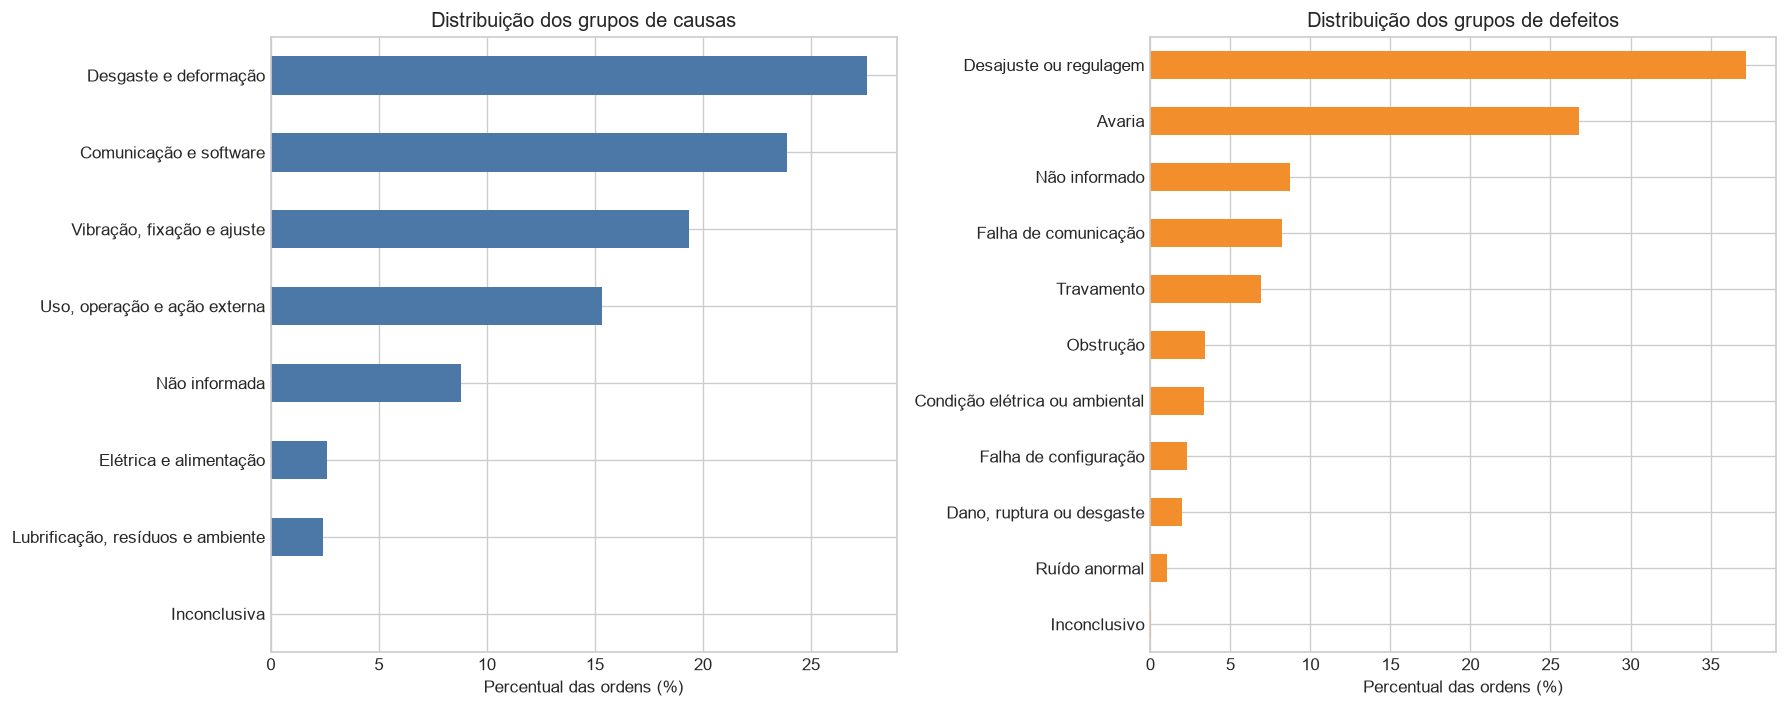

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

distribuicao_causas['Percentual'].sort_values().plot(
    kind='barh', ax=axes[0], color='#4C78A8'
)
axes[0].set_title('Distribuição dos grupos de causas')
axes[0].set_xlabel('Percentual das ordens (%)')
axes[0].set_ylabel('')

distribuicao_defeitos['Percentual'].sort_values().plot(
    kind='barh', ax=axes[1], color='#F28E2B'
)
axes[1].set_title('Distribuição dos grupos de defeitos')
axes[1].set_xlabel('Percentual das ordens (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

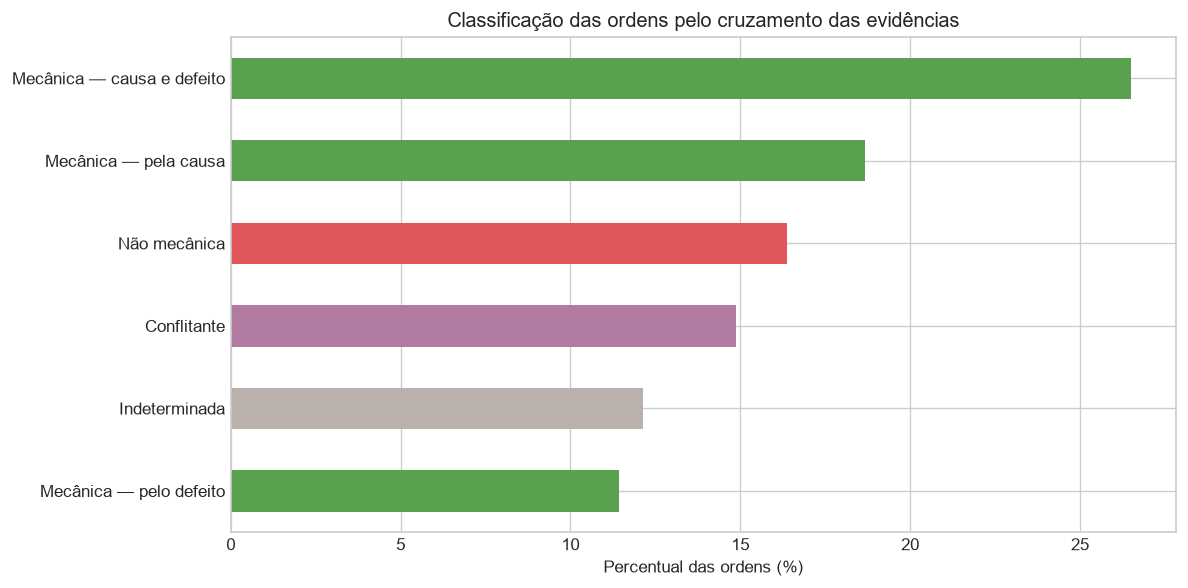

In [59]:
percentuais_classificacao = distribuicao_classificacao['Percentual'].sort_values()
cores_classificacao = [
    '#59A14F' if nome.startswith('Mecânica') else
    '#E15759' if nome == 'Não mecânica' else
    '#B07AA1' if nome == 'Conflitante' else '#BAB0AC'
    for nome in percentuais_classificacao.index
]

ax = percentuais_classificacao.plot(
    kind='barh', figsize=(10, 5), color=cores_classificacao
)
ax.set_title('Classificação das ordens pelo cruzamento das evidências')
ax.set_xlabel('Percentual das ordens (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

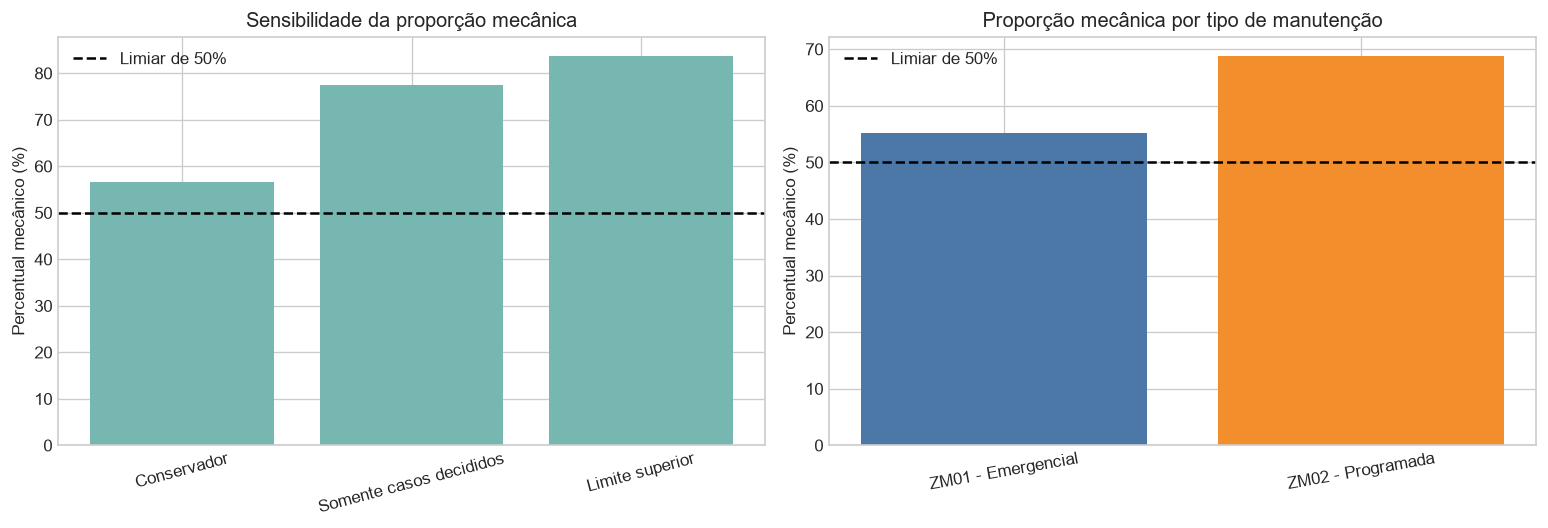

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(cenarios['Cenário'], cenarios['Percentual mecânico'], color='#76B7B2')
axes[0].axhline(50, color='black', linestyle='--', label='Limiar de 50%')
axes[0].set_title('Sensibilidade da proporção mecânica')
axes[0].set_ylabel('Percentual mecânico (%)')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend()

axes[1].bar(
    resultado_por_tipo.index,
    resultado_por_tipo['Percentual mecânico'],
    color=['#4C78A8', '#F28E2B']
)
axes[1].axhline(50, color='black', linestyle='--', label='Limiar de 50%')
axes[1].set_title('Proporção mecânica por tipo de manutenção')
axes[1].set_ylabel('Percentual mecânico (%)')
axes[1].tick_params(axis='x', rotation=10)
axes[1].legend()

plt.tight_layout()
plt.show()

### Checkpoint da etapa 9

A hipótese foi testada com todos os casos incertos tratados de maneira conservadora. As visualizações permitem verificar a composição do resultado e as diferenças entre ZM01 e ZM02.

Na próxima etapa, consolidaremos a conclusão final, as limitações da classificação e as recomendações para a continuidade do projeto de manutenção preditiva.

## 10. Conclusão da investigação

A hipótese investigativa afirma que a maior parte das manutenções corretivas está associada a falhas mecânicas de componentes. A decisão utiliza o cenário conservador, no qual casos conflitantes e indeterminados permanecem no denominador, mas não são contados como mecânicos.

In [61]:
resumo_final = pd.DataFrame({
    'Indicador': [
        'Ordens corretivas analisadas',
        'Ordens classificadas como mecânicas',
        'Percentual mecânico conservador',
        'Percentual mecânico na ZM01',
        'Percentual mecânico na ZM02',
        'Ordens conflitantes',
        'Ordens indeterminadas'
    ],
    'Resultado': [
        total_ordens,
        total_mecanicas,
        f'{percentual_mecanicas:.2f}%',
        f"{resultado_por_tipo.loc['ZM01 - Emergencial', 'Percentual mecânico']:.2f}%",
        f"{resultado_por_tipo.loc['ZM02 - Programada', 'Percentual mecânico']:.2f}%",
        total_conflitantes,
        total_indeterminadas
    ]
})

display(resumo_final)

if percentual_mecanicas > 50:
    print('Conclusão: a Hipótese 7 é sustentada pelos dados no cenário conservador.')
else:
    print('Conclusão: a Hipótese 7 não é sustentada pelos dados no cenário conservador.')

,Indicador,Resultado
0,Ordens corretivas analisadas,11655
1,Ordens classificadas como mecânicas,6598
2,Percentual mecânico conservador,56.61%
3,Percentual mecânico na ZM01,55.29%
4,Percentual mecânico na ZM02,68.73%
5,Ordens conflitantes,1733
6,Ordens indeterminadas,1415


Conclusão: a Hipótese 7 é sustentada pelos dados no cenário conservador.


### 10.1 Interpretação dos resultados

A **Hipótese 7 é sustentada para o conjunto de dados e para os critérios adotados nesta investigação**. No cenário conservador, 56,61% das ordens foram classificadas como mecânicas, superando o limiar de 50%. O resultado também aparece separadamente nas duas modalidades: 55,29% na ZM01 e 68,73% na ZM02.

Os agrupamentos ajudam a explicar esse resultado:

- `Desgaste e deformação` é o maior grupo de causas, com 27,58%;
- `Vibração, fixação e ajuste` representa 19,37%;
- Nos defeitos, `Desajuste ou regulagem` é o modo mais frequente, com 37,23%;
- `Avaria` representa 26,76%, mas foi mantida como evidência indeterminada por ser uma descrição genérica;
- Comunicação e software também possuem participação relevante, mostrando que o sistema não deve ser analisado apenas pela perspectiva mecânica.

Portanto, falhas mecânicas constituem a maioria observada, mas coexistem com ocorrências importantes de comunicação, software, energia e registros sem diagnóstico conclusivo.

### 10.2 Limitações

1. **Classificação baseada em regras:** os grupos e as evidências foram definidos a partir dos textos cadastrados e precisam ser validados por especialistas de manutenção.
2. **Diagnósticos conflitantes:** 1.733 ordens apresentam divergência entre a evidência da causa e a do defeito.
3. **Casos indeterminados:** 1.415 ordens não possuem informação suficiente para uma decisão.
4. **Campos ausentes:** existem 1.025 causas e 1.020 defeitos ausentes na base preparada.
5. **Ordens repetidas:** números repetidos foram excluídos de forma conservadora devido a diagnósticos divergentes.
6. **Ausência de exposição operacional:** a contagem não foi normalizada pelo número de portas, ciclos de abertura, tempo de operação ou quantidade de trens.
7. **Escopo histórico:** o resultado descreve as ordens presentes nas planilhas e não garante que a mesma proporção ocorrerá no futuro.
8. **Associação não implica causalidade:** a análise identifica padrões nos registros, mas não demonstra a causa física de cada falha.

### 10.3 Recomendações para continuidade

1. Validar os grupos de causas e defeitos com a equipe de engenharia e manutenção;
2. Revisar uma amostra das ordens conflitantes e indeterminadas para aprimorar as regras;
3. Investigar separadamente os números de ordem repetidos antes de reincorporá-los;
4. Criar uma taxonomia oficial de causa, defeito e componente no processo de registro;
5. Cruzar as ordens com estação, porta, componente e período para identificar pontos críticos;
6. Integrar alarmes, ciclos de abertura, tempo de operação e histórico de substituições;
7. Utilizar os grupos validados como possíveis rótulos para futuros modelos supervisionados;
8. Monitorar principalmente desgaste, vibração, fixação e desajustes, pois concentram parte relevante das ocorrências mecânicas.

### Encerramento

A investigação foi conduzida de forma rastreável: definição do escopo, inspeção e limpeza das bases, padronização textual, agrupamento de causas e defeitos, cruzamento das evidências, teste conservador e análise de sensibilidade.

O principal resultado é que as falhas mecânicas representam a maioria das ordens corretivas analisadas, com destaque para desgaste, vibração, fixação e desajustes. Ao mesmo tempo, a quantidade de conflitos e diagnósticos ausentes reforça a necessidade de melhorar a qualidade dos registros antes de treinar modelos preditivos.